<a href="https://colab.research.google.com/github/NietoEmmanuel/SIMULACION-II/blob/main/Modelo_SIR_PyMC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelo SIR con PyMC (enfoque bayesiano)



**RECORDAR:** posterior ∝ verosimilitud × priori

* **Priori:** lo que creemos de beta y gamma antes de ver los datos. Aquí usamos uniformes, o sea que cualquier valor entre los límites es igual de probable.
* **Verosimilitud:** qué tan probables son los datos si beta y gamma valen cierto número.
* **Posterior:** lo que creemos de beta y gamma después de ver los datos. Es lo que nos da Metropolis.

Ponemos ∝ y no = porque para estimar parámetros no necesitamos calcular la evidencia, P(datos | I). Metropolis solo compara un punto con otro y esa constante se cancela. La evidencia solo se necesita para comparar modelos.

In [3]:
!pip install pymc

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import pytensor.tensor as pt
from pytensor.compile.ops import as_op
from scipy.integrate import solve_ivp
from scipy.stats import chi2, gaussian_kde
from matplotlib.patches import Ellipse

# datos: infectados en cada uno de los 15 días
dias = np.arange(15)
infectados = np.array([1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4])

N = 763

In [5]:
# ecuaciones del modelo SIR
# beta es la tasa de contagio y gamma la tasa de recuperación
def sir(t, y, beta, gamma):
    S, I, R = y
    dS = -beta * S * I / N
    dI = beta * S * I / N - gamma * I
    dR = gamma * I
    return [dS, dI, dR]


@as_op(itypes=[pt.dscalar, pt.dscalar], otypes=[pt.dvector])
def infectados_modelo(beta, gamma):
    # al inicio hay 762 sanos, 1 infectado y 0 recuperados
    sol = solve_ivp(sir, (0, 14), [N - 1, 1, 0], t_eval=dias, args=(float(beta), float(gamma)))
    return sol.y[1]

/tmp/ipykernel_10382/400268913.py:11: FutureWarning: pytensor.as_op is deprecated and will be removed in a future release. Please use pytensor.wrap_py instead.
  @as_op(itypes=[pt.dscalar, pt.dscalar], otypes=[pt.dvector])


In [6]:
with pm.Model() as modelo_bayesiano:
    # PRIOR: lo que suponemos antes de ver los datos
    # uniforme: cualquier valor entre los límites es igual de probable
    beta = pm.Uniform("beta", lower=0.5, upper=3.0)
    gamma = pm.Uniform("gamma", lower=0.1, upper=1.5)

    #error de los datos
    sigma = pm.HalfNormal("sigma", sigma=15)

    # VEROSIMILITUD: los datos reales tienen que quedar cerca de la curva del modelo
    # (normal alrededor de la curva, con desviación sigma)
    pm.Normal("observaciones", mu=infectados_modelo(beta, gamma), sigma=sigma, observed=infectados)


    # draws = muestras que guardamos, tune = pasos de calentamiento que se tiran, chains = cadenas
    trace = pm.sample(draws=20000, tune=5000, chains=4, cores=1, step=pm.Metropolis(), random_seed=42)

 Progress                                   Draw    Scaling   Accept Rate   Speed           Elapsed   Remaining  
 ──────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   25000   0.16      1.39          67.28 draws/s   0:06:11   0:00:00    
  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   25000   0.16      0.21          34.23 draws/s   0:12:10   0:00:00    
  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   25000   0.16      0.00          22.95 draws/s   0:18:09   0:00:00    
  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━   25000   0.16      0.00          17.16 draws/s   0:24:17   0:00:00

beta = 1.6655982573282475
gamma = 0.44695293629860033
sigma = 18.921230845918437


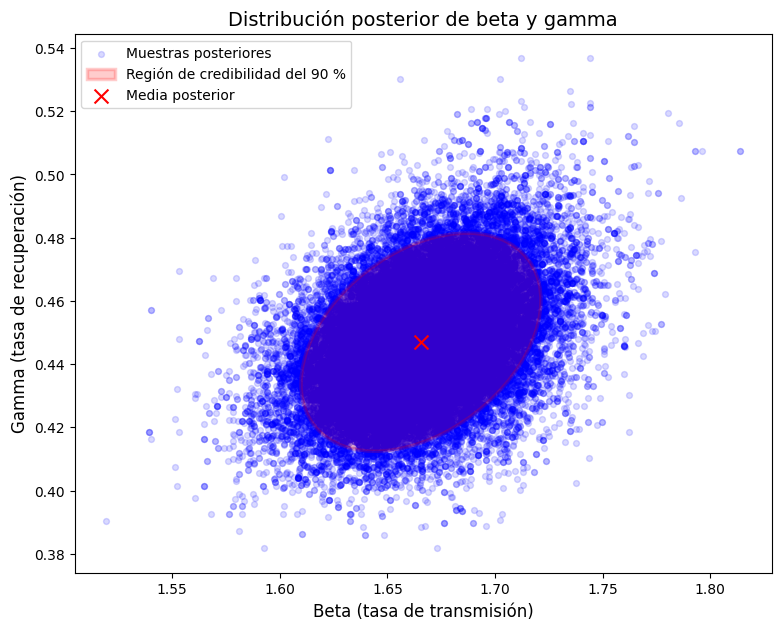

In [9]:
# sacamos las muestras de beta, gamma y sigma (juntando las 4 cadenas)
beta_post = trace.posterior["beta"].values.flatten()
gamma_post = trace.posterior["gamma"].values.flatten()
sigma_post = trace.posterior["sigma"].values.flatten()

# el promedio de cada una es nuestro valor estimado
print("beta =", beta_post.mean())
print("gamma =", gamma_post.mean())
print("sigma =", sigma_post.mean())

# ELIPSE DEL 90 %
# es la región donde beta y gamma están juntas con 90 % de probabilidad
muestras = np.column_stack([beta_post, gamma_post])
centro = muestras.mean(axis=0)
covarianza = np.cov(muestras, rowvar=False)


autovalores, autovectores = np.linalg.eigh(covarianza)
factor = chi2.ppf(0.90, df=2)

ancho = 2 * np.sqrt(autovalores[1] * factor)
alto = 2 * np.sqrt(autovalores[0] * factor)
angulo = np.degrees(np.arctan2(autovectores[1, 1], autovectores[0, 1]))

# gráfica: puntos azules = muestras, elipse roja = región del 90 %, x roja = promedio
plt.figure(figsize=(9, 7))
plt.scatter(beta_post, gamma_post, color='blue', alpha=0.15, s=18, label='Muestras posteriores')
elipse = Ellipse(xy=centro, width=ancho, height=alto, angle=angulo,
                 facecolor='red', edgecolor='red', alpha=0.2, linewidth=2.5,
                 label='Región de credibilidad del 90 %')
plt.gca().add_patch(elipse)
plt.scatter(centro[0], centro[1], color='red', marker='x', s=100, label='Media posterior')
plt.xlabel("Beta (tasa de transmisión)", fontsize=12)
plt.ylabel("Gamma (tasa de recuperación)", fontsize=12)
plt.title("Distribución posterior de beta y gamma", fontsize=14)
plt.legend()
plt.show()

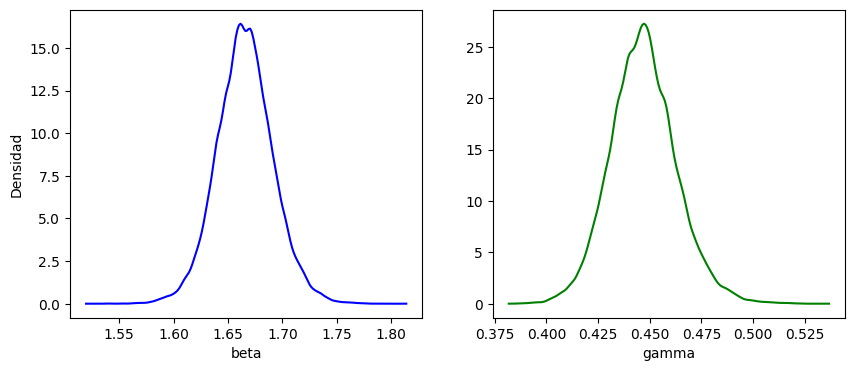

In [8]:

x_beta = np.linspace(beta_post.min(), beta_post.max(), 200)
x_gamma = np.linspace(gamma_post.min(), gamma_post.max(), 200)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(x_beta, gaussian_kde(beta_post)(x_beta), color='blue')
plt.xlabel("beta")
plt.ylabel("Densidad")

plt.subplot(1, 2, 2)
plt.plot(x_gamma, gaussian_kde(gamma_post)(x_gamma), color='green')
plt.xlabel("gamma")

plt.show()